In [1]:
# Cell 1: Setup — resolve paths, import modules
import sys
from pathlib import Path

# Find repo root no matter where the notebook lives
CWD = Path.cwd()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

# Make src/ importable
sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from clustering import (
    load_cluster_input,
    evaluate_k_range,
    plot_k_selection,
    fit_kmeans,
    fit_dbscan,
    fit_hierarchical,
    plot_clusters_pca,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

print(f"Repo root: {REPO_ROOT}")
print(f"Data dir:  {REPO_ROOT / 'data' / 'processed'}")
print(f"Exists?    {(REPO_ROOT / 'data' / 'processed' / 'cluster_input.joblib').exists()}")

Repo root: e:\VSCODE PROGRAMS\malawi-power-predictor
Data dir:  e:\VSCODE PROGRAMS\malawi-power-predictor\data\processed
Exists?    True


In [2]:
# Cell 2: Load scaled X, metadata, and feature names
X, meta, feature_cols = load_cluster_input()

print(f"X shape:      {X.shape}")
print(f"Features:     {feature_cols}")
print(f"Meta columns: {list(meta.columns)}")
print(f"Meta rows:    {len(meta)}")
print("\nMeta head:")
meta.head()

X shape:      (200, 5)
Features:     ['mean_daily_kwh', 'max_hourly_kwh', 'midday_ratio', 'volatility_cv', 'evening_ratio']
Meta columns: ['household_id', 'area', 'region', 'household_size', 'is_urban']
Meta rows:    200

Meta head:


,household_id,area,region,household_size,is_urban
0,0,rural,South,3,0
1,1,urban,South,5,1
2,2,rural,South,6,0
3,3,rural,Central,2,0
4,4,urban,South,6,1


In [3]:
# Cell 3: Evaluate K-Means for k = 2..10
rows = evaluate_k_range(X, k_range=range(2, 11))
df_scores = pd.DataFrame(rows).round(3)
df_scores

,k,inertia,silhouette,davies_bouldin
0,2,680.788,0.302,1.282
1,3,475.163,0.359,1.130
2,4,352.656,0.415,0.868
3,5,282.778,0.386,0.941
4,6,237.855,0.404,0.909
5,7,207.554,0.406,0.909
6,8,179.111,0.402,0.897
7,9,167.547,0.366,0.910
8,10,155.733,0.369,0.974


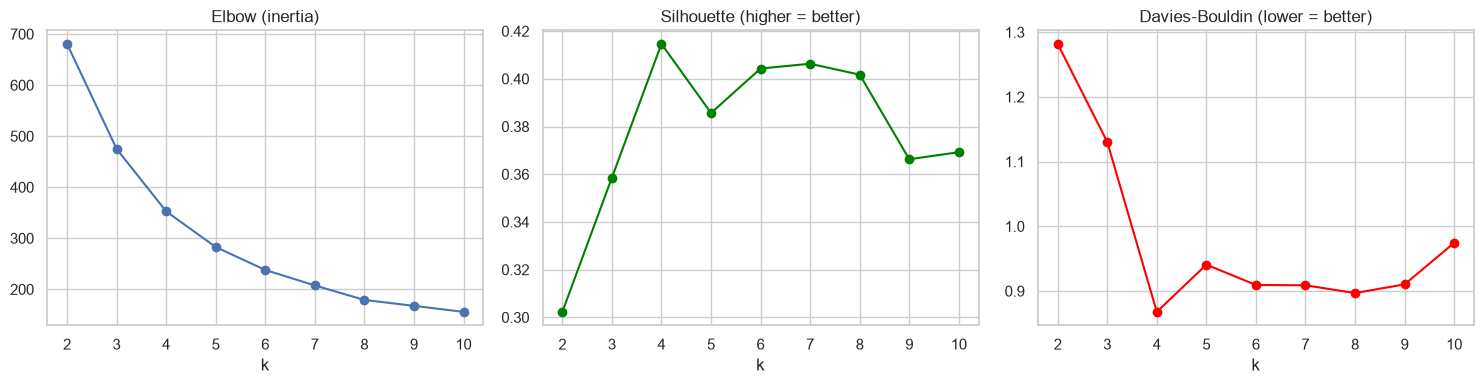

In [4]:
# Cell 4: Visualize the elbow / silhouette / DB curves
plot_k_selection(rows)
plt.tight_layout()
plt.show()

In [11]:
# Cell 5: Fit K-Means
K_BEST = 4   # ← change based on the elbow/silhouette plot

labels, km = fit_kmeans(X, K_BEST)

# Attach labels to metadata
meta_labeled = meta.copy()
meta_labeled["cluster"] = labels

# Pull raw feature values for interpretation
raw = pd.read_csv(REPO_ROOT / "data" / "processed" / "household_features.csv")
meta_labeled = meta_labeled.merge(
    raw[["household_id"] + feature_cols],
    on="household_id",
    how="left",
)

print(f"K-Means fitted with k = {K_BEST}")
print(f"Cluster sizes:")
print(meta_labeled["cluster"].value_counts().sort_index())
print(f"\nUrban share per cluster:")
print(meta_labeled.groupby("cluster")["is_urban"].mean().round(2))
print(f"\nMean feature profile per cluster:")
print(meta_labeled.groupby("cluster")[feature_cols].mean().round(3))

K-Means fitted with k = 4
Cluster sizes:
cluster
0    28
1    38
2    88
3    46
Name: count, dtype: int64

Urban share per cluster:
cluster
0    0.25
1    0.13
2    0.11
3    0.91
Name: is_urban, dtype: float64

Mean feature profile per cluster:
         mean_daily_kwh  max_hourly_kwh  midday_ratio  volatility_cv  \
cluster                                                                
0                 1.384           1.541         0.169          2.721   
1                 1.225           4.979         0.092          7.236   
2                 1.833           2.340         0.054          2.705   
3                 6.318          10.846         0.118          3.504   

         evening_ratio  
cluster                 
0                0.504  
1                0.501  
2                0.746  
3                0.587  


In [12]:
# Cell 6: Do the clusters align with urban/rural?
ct = pd.crosstab(meta_labeled["cluster"], meta_labeled["area"], margins=True)
ct

area,rural,urban,All
cluster,,,
0,21,7,28
1,33,5,38
2,78,10,88
3,4,42,46
All,136,64,200


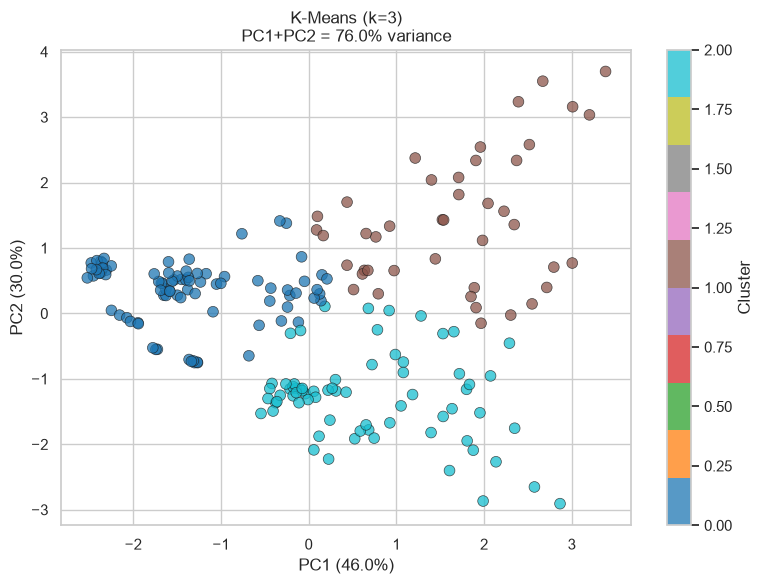

In [7]:
# Cell 7: Visualize clusters in 2D
fig, X_2d = plot_clusters_pca(X, labels, title=f"K-Means (k={K_BEST})")
plt.show()

DBSCAN clusters found: 4
Noise points (label -1): 30


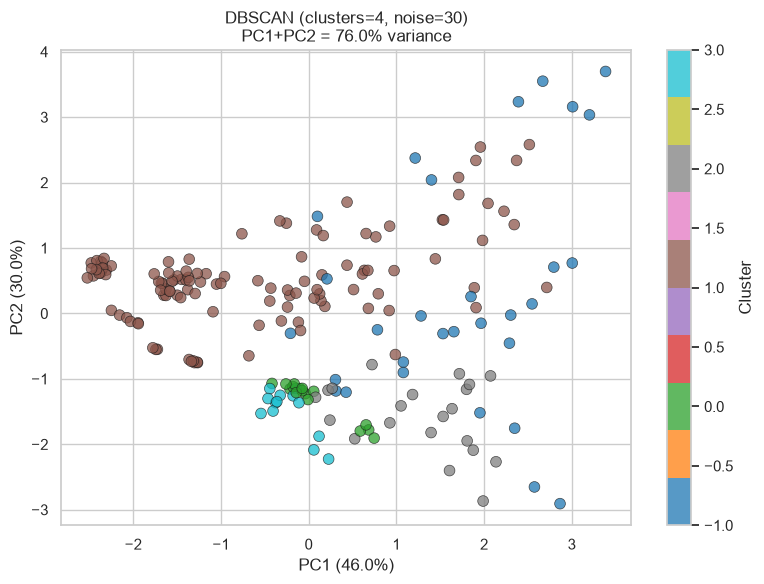

In [8]:
# Cell 8: DBSCAN — no need to pre-specify k
db_labels, db_model = fit_dbscan(X, eps=0.9, min_samples=5)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()

print(f"DBSCAN clusters found: {n_clusters}")
print(f"Noise points (label -1): {n_noise}")

fig, _ = plot_clusters_pca(X, db_labels, title=f"DBSCAN (clusters={n_clusters}, noise={n_noise})")
plt.show()

Agreement between K-Means and Hierarchical:
  Adjusted Rand Index = 0.739
  (1.0 = perfect agreement, 0.0 = random)


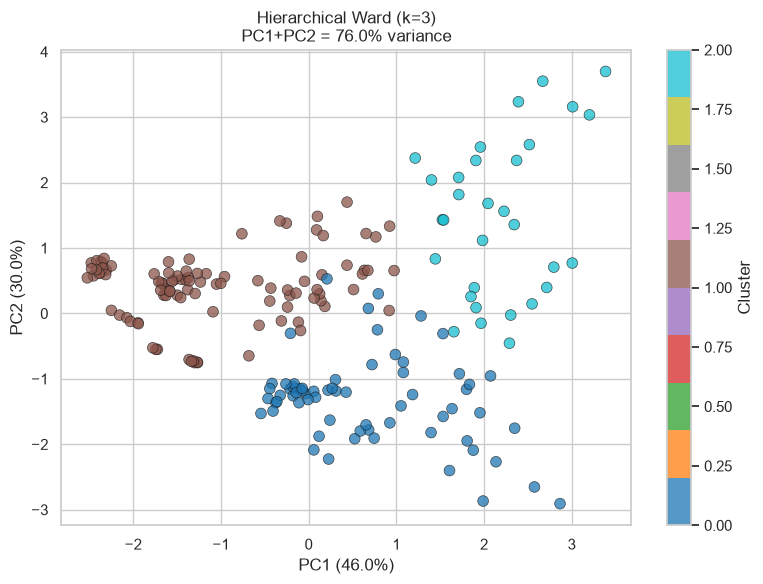

In [9]:
# Cell 9: Hierarchical (Ward linkage)
hc_labels, hc_model = fit_hierarchical(X, k=K_BEST, linkage="ward")

print("Agreement between K-Means and Hierarchical:")
from sklearn.metrics import adjusted_rand_score
print(f"  Adjusted Rand Index = {adjusted_rand_score(labels, hc_labels):.3f}")
print("  (1.0 = perfect agreement, 0.0 = random)")

fig, _ = plot_clusters_pca(X, hc_labels, title=f"Hierarchical Ward (k={K_BEST})")
plt.show()

In [10]:
# Cell 10: Persist cluster labels for later use
out = REPO_ROOT / "data" / "processed" / "household_clusters.csv"
meta_labeled[["household_id", "area", "region",
              "household_size"] + feature_cols + ["cluster"]].to_csv(out, index=False)
print(f"Saved: {out}")

Saved: e:\VSCODE PROGRAMS\malawi-power-predictor\data\processed\household_clusters.csv


In [13]:
# Cell 11: Attach human-readable names
CLUSTER_NAMES = {
    0: "flat_daytime",
    1: "spiky_low",
    2: "evening_peak_rural",
    3: "high_use_urban",
}
meta_labeled["cluster_name"] = meta_labeled["cluster"].map(CLUSTER_NAMES)

out = REPO_ROOT / "data" / "processed" / "household_clusters_named.csv"
meta_labeled.to_csv(out, index=False)
print(f"Saved: {out}")
print(meta_labeled.groupby("cluster_name").size())

Saved: e:\VSCODE PROGRAMS\malawi-power-predictor\data\processed\household_clusters_named.csv
cluster_name
evening_peak_rural    88
flat_daytime          28
high_use_urban        46
spiky_low             38
dtype: int64


In [14]:
# Cell 12: Summary table
summary = meta_labeled.groupby("cluster_name").agg(
    n_households=("household_id", "count"),
    pct_urban=("is_urban", lambda s: f"{s.mean():.0%}"),
    mean_kwh_day=("mean_daily_kwh", "mean"),
    peak_kwh=("max_hourly_kwh", "mean"),
    evening_share=("evening_ratio", "mean"),
    daytime_share=("midday_ratio", "mean"),
).round(2)
summary["pct_of_total"] = (summary["n_households"] / len(meta_labeled) * 100).round(1).astype(str) + "%"
print(summary.to_string())

                    n_households pct_urban  mean_kwh_day  peak_kwh  evening_share  daytime_share pct_of_total
cluster_name                                                                                                 
evening_peak_rural            88       11%          1.83      2.34           0.75           0.05        44.0%
flat_daytime                  28       25%          1.38      1.54           0.50           0.17        14.0%
high_use_urban                46       91%          6.32     10.85           0.59           0.12        23.0%
spiky_low                     38       13%          1.23      4.98           0.50           0.09        19.0%
